# 03 Models

PLAN.md steps 3-4: baselines and XGBoost, leave-one-match-out, open play only. Logic in `src/passmodel/models.py`; this notebook reads `results/`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from passmodel.load import REPO_ROOT

RESULTS = REPO_ROOT / "results"
metrics = pd.read_csv(RESULTS / "metrics_per_fold.csv")
predictions = pd.read_csv(RESULTS / "predictions.csv")

## Held-out metrics per fold (fold = test match)
Lower log loss and Brier are better; higher ROC-AUC is better.

In [2]:
metrics

,model,fold,n,log_loss,roc_auc,brier
0,constant,1,952.0000,0.5710,0.5000,0.1904
1,constant,2,1083.0000,0.4800,0.5000,0.1507
2,constant,3,1309.0000,0.5111,0.5000,0.1647
3,constant,mean,1114.6667,0.5207,0.5000,0.1686
4,logistic (pass length),1,952.0000,0.5664,0.5718,0.1887
5,logistic (pass length),2,1083.0000,0.4790,0.5534,0.1504
6,logistic (pass length),3,1309.0000,0.5093,0.5542,0.1639
7,logistic (pass length),mean,1114.6667,0.5183,0.5598,0.1677
8,logistic (pitch control),1,952.0000,0.5618,0.6260,0.1870
9,logistic (pitch control),2,1083.0000,0.4798,0.5846,0.1516


In [3]:
metrics.pivot(index="model", columns="fold", values="log_loss")

fold,1,2,3,mean
model,,,,
constant,0.5710,0.4800,0.5111,0.5207
logistic (pass length),0.5664,0.4790,0.5093,0.5183
logistic (pitch control),0.5618,0.4798,0.4949,0.5121
"xgboost (inner-CV tuned, sensitivity)",0.5105,0.4216,0.4462,0.4594
xgboost (single target + pitch control),0.5160,0.4213,0.4604,0.4659
xgboost (single target),0.5201,0.4186,0.4541,0.4643
xgboost (target mixture),0.5037,0.4118,0.4504,0.4553


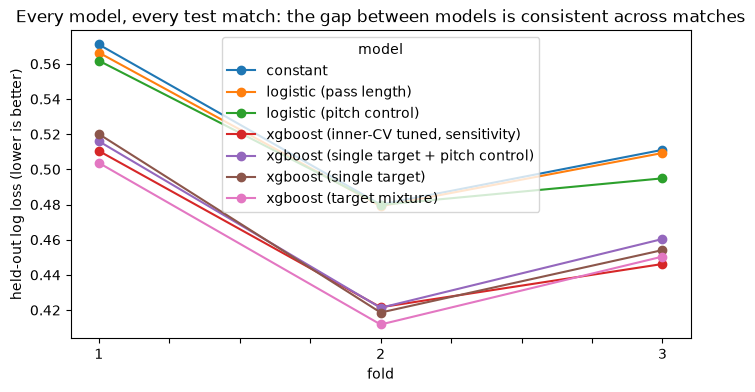

In [4]:
pivot = metrics[metrics["fold"] != "mean"].pivot(index="fold", columns="model", values="log_loss")
ax = pivot.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("held-out log loss (lower is better)")
ax.set_title("Every model, every test match: the gap between models is consistent across matches");

## D4 sensitivity: what inner CV would have chosen

In [5]:
inner = pd.read_csv(RESULTS / "d4_inner_cv.csv")
inner[inner["chosen"]]

,fold,max_depth,learning_rate,n_estimators,inner_log_loss,chosen
0,1,2,0.03,200,0.4414,True
12,2,2,0.03,200,0.4849,True
24,3,2,0.03,200,0.4811,True


In [6]:
inner.pivot_table(index=["max_depth", "learning_rate", "n_estimators"], columns="fold", values="inner_log_loss").round(4)

fold                                       1       2       3
max_depth learning_rate n_estimators                        
2         0.03          200           0.4414  0.4849  0.4811
                        500           0.4502  0.4930  0.4902
          0.10          200           0.4582  0.5036  0.4993
                        500           0.4951  0.5524  0.5509
3         0.03          200           0.4442  0.4869  0.4829
                        500           0.4638  0.5096  0.5065
          0.10          200           0.4800  0.5234  0.5282
                        500           0.5492  0.6070  0.6153
4         0.03          200           0.4496  0.4915  0.4881
                        500           0.4797  0.5255  0.5256
          0.10          200           0.5020  0.5458  0.5577
                        500           0.5846  0.6548  0.6552

## Predicted probabilities by outcome (XGBoost, held out)

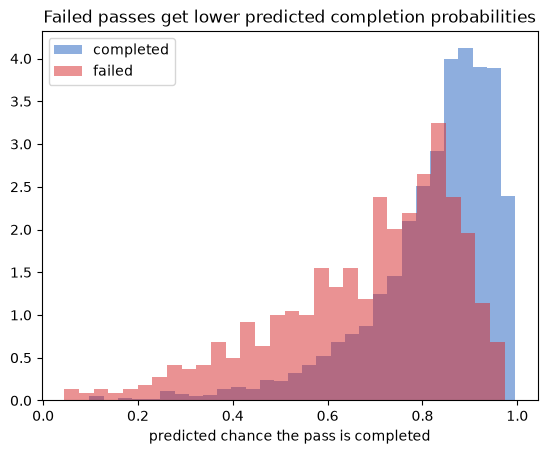

In [7]:
x = predictions[predictions["model"] == "xgboost (target mixture)"]
for done, colour, label in [(True, "#1f5fbf", "completed"), (False, "#d62728", "failed")]:
    plt.hist(x.loc[x["completed"] == done, "p_complete"], bins=30, alpha=0.5, density=True, color=colour, label=label)
plt.xlabel("predicted chance the pass is completed")
plt.legend()
plt.title("Failed passes get lower predicted completion probabilities");